# Retrain với Graph Features + Error Analysis

**Part 1** — Retrain 4 models với 34 graph-enhanced features. So sánh PR-AUC trước/sau.  
**Part 2** — Error Analysis trên False Negatives của best model.

> Best params từ Optuna — không retune lại.

## 1. Imports & Config

In [1]:
import os, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.ensemble import BalancedRandomForestClassifier
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.metrics import (
    f1_score, fbeta_score, recall_score, precision_score,
    roc_auc_score, average_precision_score,
    precision_recall_curve, confusion_matrix
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
SEED = 42
DATA_PATH = r'D:/AI66A_group_10_Topic_7/src/data/processed'

def p(fname): return os.path.join(DATA_PATH, fname)

def metrics(y_true, y_prob, threshold=0.5, label=''):
    y_pred = (y_prob >= threshold).astype(int)
    r = {
        'PR-AUC':    round(average_precision_score(y_true, y_prob), 4),
        'F2':        round(fbeta_score(y_true, y_pred, beta=2), 4),
        'F1':        round(f1_score(y_true, y_pred), 4),
        'Recall':    round(recall_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred), 4),
        'ROC-AUC':   round(roc_auc_score(y_true, y_prob), 4),
    }
    if label:
        print(f'{label:30s}  PR-AUC={r["PR-AUC"]}  F2={r["F2"]}  Recall={r["Recall"]}')
    return r

print('Ready.')

Ready.


## 2. Load Data

In [2]:
# Baseline (28 features)
X_train      = joblib.load(p('X_train.pkl'))
y_train      = joblib.load(p('y_train.pkl'))
X_train_res  = joblib.load(p('X_train_res.pkl'))
y_train_res  = joblib.load(p('y_train_res.pkl'))
X_val        = joblib.load(p('X_val.pkl'))
y_val        = joblib.load(p('y_val.pkl'))
X_test       = joblib.load(p('X_test.pkl'))
y_test       = joblib.load(p('y_test.pkl'))
feature_cols = joblib.load(p('feature_cols.pkl'))
encoders     = joblib.load(p('encoders.pkl'))

# Graph-enhanced (34 features)
X_train_g      = joblib.load(p('X_train_graph.pkl'))       # BRF: imbalanced
X_train_res_g  = joblib.load(p('X_train_res_graph.pkl'))   # LGB/XGB/CAT: SMOTE
X_val_g        = joblib.load(p('X_val_graph.pkl'))
X_test_g       = joblib.load(p('X_test_graph.pkl'))
feature_cols_g = joblib.load(p('feature_cols_graph.pkl'))

MODEL_NAMES = ['BRF', 'LightGBM', 'XGBoost', 'CatBoost']
print(f'Baseline: {len(feature_cols)} features  |  Graph: {len(feature_cols_g)} features')
print(f'New: {feature_cols_g[28:]}')

Baseline: 28 features  |  Graph: 34 features
New: ['customer_degree', 'merchant_degree', 'merchant_fraud_rate', 'customer_fraud_rate', 'customer_pagerank', 'merchant_pagerank']


---
# Part 1 — Retrain với Graph Features

## 3. Train Baseline Models (28 features)

In [3]:
print('Training BRF baseline ...')
brf_base = BalancedRandomForestClassifier(
    n_estimators=1279, max_depth=12, min_samples_leaf=8, min_samples_split=8,
    max_features='sqrt', sampling_strategy='auto', random_state=SEED, n_jobs=-1
)
brf_base.fit(X_train, y_train)
print('BRF baseline done.')

Training BRF baseline ...
BRF baseline done.


In [4]:
print('Training LightGBM baseline ...')
lgb_base = lgb.LGBMClassifier(
    n_estimators=1588, max_depth=8, learning_rate=0.011111730153570632,
    num_leaves=262, min_child_samples=6, subsample=0.7675345232911098,
    colsample_bytree=0.5125626108583482, random_state=SEED, n_jobs=-1, verbose=-1
)
lgb_base.fit(X_train_res, y_train_res)
print('LightGBM baseline done.')

Training LightGBM baseline ...
LightGBM baseline done.


In [5]:
print('Training XGBoost baseline ...')
xgb_base = xgb.XGBClassifier(
    n_estimators=1373, max_depth=8, learning_rate=0.0070295261563991405,
    subsample=0.9973124683007342, colsample_bytree=0.5225725607254758,
    min_child_weight=13, scale_pos_weight=5.084119553737549,
    random_state=SEED, n_jobs=-1, tree_method='hist', eval_metric='aucpr', verbosity=0
)
xgb_base.fit(X_train_res, y_train_res)
print('XGBoost baseline done.')

Training XGBoost baseline ...
XGBoost baseline done.


In [6]:
print('Training CatBoost baseline ...')
cat_base = CatBoostClassifier(
    iterations=713, depth=7, learning_rate=0.017192185918036892,
    l2_leaf_reg=4.504532217224262, subsample=0.523096799516844,
    colsample_bylevel=0.5347915807593706, min_data_in_leaf=27,
    random_seed=SEED, eval_metric='AUC', verbose=0
)
cat_base.fit(X_train_res, y_train_res)
print('CatBoost baseline done.')

Training CatBoost baseline ...
CatBoost baseline done.


In [7]:
base_probs = {
    'BRF':      brf_base.predict_proba(X_test)[:, 1],
    'LightGBM': lgb_base.predict_proba(X_test)[:, 1],
    'XGBoost':  xgb_base.predict_proba(X_test)[:, 1],
    'CatBoost': cat_base.predict_proba(X_test)[:, 1],
}
print('Baseline test PR-AUC:')
for name, probs in base_probs.items():
    print(f'  {name:10s}: {average_precision_score(y_test, probs):.4f}')

Baseline test PR-AUC:
  BRF       : 0.8892
  LightGBM  : 0.9319
  XGBoost   : 0.9306
  CatBoost  : 0.9302


## 4. Train Graph-Enhanced Models (34 features)

In [8]:
print('Training BRF graph ...')
brf_graph = BalancedRandomForestClassifier(
    n_estimators=1279, max_depth=12, min_samples_leaf=8, min_samples_split=8,
    max_features='sqrt', sampling_strategy='auto', random_state=SEED, n_jobs=-1
)
brf_graph.fit(X_train_g, y_train)
print('BRF graph done.')

Training BRF graph ...
BRF graph done.


In [9]:
print('Training LightGBM graph ...')
lgb_graph = lgb.LGBMClassifier(
    n_estimators=1588, max_depth=8, learning_rate=0.011111730153570632,
    num_leaves=262, min_child_samples=6, subsample=0.7675345232911098,
    colsample_bytree=0.5125626108583482, random_state=SEED, n_jobs=-1, verbose=-1
)
lgb_graph.fit(X_train_res_g, y_train_res)
print('LightGBM graph done.')

Training LightGBM graph ...
LightGBM graph done.


In [10]:
print('Training XGBoost graph ...')
xgb_graph = xgb.XGBClassifier(
    n_estimators=1373, max_depth=8, learning_rate=0.0070295261563991405,
    subsample=0.9973124683007342, colsample_bytree=0.5225725607254758,
    min_child_weight=13, scale_pos_weight=5.084119553737549,
    random_state=SEED, n_jobs=-1, tree_method='hist', eval_metric='aucpr', verbosity=0
)
xgb_graph.fit(X_train_res_g, y_train_res)
print('XGBoost graph done.')

Training XGBoost graph ...
XGBoost graph done.


In [11]:
print('Training CatBoost graph ...')
cat_graph = CatBoostClassifier(
    iterations=713, depth=7, learning_rate=0.017192185918036892,
    l2_leaf_reg=4.504532217224262, subsample=0.523096799516844,
    colsample_bylevel=0.5347915807593706, min_data_in_leaf=27,
    random_seed=SEED, eval_metric='AUC', verbose=0
)
cat_graph.fit(X_train_res_g, y_train_res)
print('CatBoost graph done.')

Training CatBoost graph ...
CatBoost graph done.


In [12]:
graph_val_probs = {
    'BRF':      brf_graph.predict_proba(X_val_g)[:, 1],
    'LightGBM': lgb_graph.predict_proba(X_val_g)[:, 1],
    'XGBoost':  xgb_graph.predict_proba(X_val_g)[:, 1],
    'CatBoost': cat_graph.predict_proba(X_val_g)[:, 1],
}
graph_test_probs = {
    'BRF':      brf_graph.predict_proba(X_test_g)[:, 1],
    'LightGBM': lgb_graph.predict_proba(X_test_g)[:, 1],
    'XGBoost':  xgb_graph.predict_proba(X_test_g)[:, 1],
    'CatBoost': cat_graph.predict_proba(X_test_g)[:, 1],
}
print('Graph test PR-AUC:')
for name, probs in graph_test_probs.items():
    print(f'  {name:10s}: {average_precision_score(y_test, probs):.4f}')

Graph test PR-AUC:
  BRF       : 0.8429
  LightGBM  : 0.9120
  XGBoost   : 0.9149
  CatBoost  : 0.9247


## 5. Comparison Table & PR Curves

In [13]:
rows = []
for name in MODEL_NAMES:
    mb = metrics(y_test, base_probs[name])
    mg = metrics(y_test, graph_test_probs[name])
    mv = metrics(y_val,  graph_val_probs[name])
    rows.append({
        'Model':           name,
        'Baseline PR-AUC': mb['PR-AUC'],
        'Graph PR-AUC':    mg['PR-AUC'],
        'Δ PR-AUC':        round(mg['PR-AUC'] - mb['PR-AUC'], 4),
        'Baseline F2':     mb['F2'],
        'Graph F2':        mg['F2'],
        'Δ F2':            round(mg['F2'] - mb['F2'], 4),
        'Graph Recall':    mg['Recall'],
        'Graph Precision': mg['Precision'],
        'Val PR-AUC':      mv['PR-AUC'],
    })

comparison_df = pd.DataFrame(rows).set_index('Model')

def color_delta(val):
    return 'color: green' if val > 0 else ('color: red' if val < 0 else '')

display(
    comparison_df.style
    .applymap(color_delta, subset=['Δ PR-AUC', 'Δ F2'])
    .format(precision=4)
    .set_caption('Baseline vs Graph-Enhanced — Test Set')
)

,Baseline PR-AUC,Graph PR-AUC,Δ PR-AUC,Baseline F2,Graph F2,Δ F2,Graph Recall,Graph Precision,Val PR-AUC
Model,,,,,,,,,
BRF,0.8892,0.8429,-0.0463,0.7740,0.7081,-0.0659,0.8181,0.4605,0.8603
LightGBM,0.9319,0.9120,-0.0199,0.7659,0.7636,-0.0023,0.7360,0.8985,0.9272
XGBoost,0.9306,0.9149,-0.0157,0.8542,0.8356,-0.0186,0.8482,0.7884,0.9318
CatBoost,0.9302,0.9247,-0.0055,0.8023,0.8053,0.0030,0.7859,0.8936,0.9368


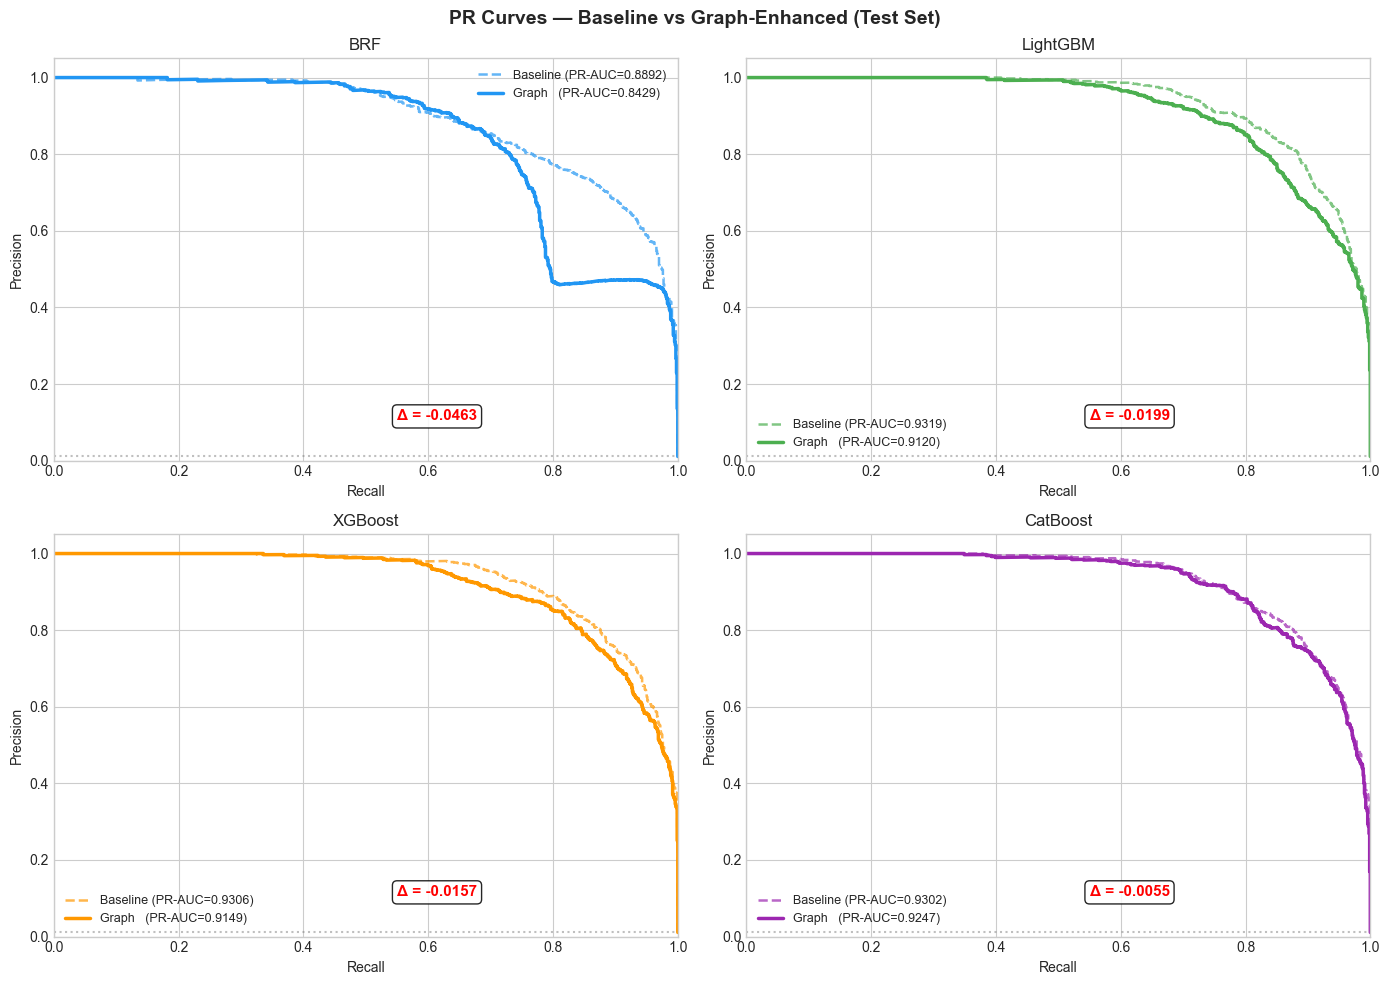

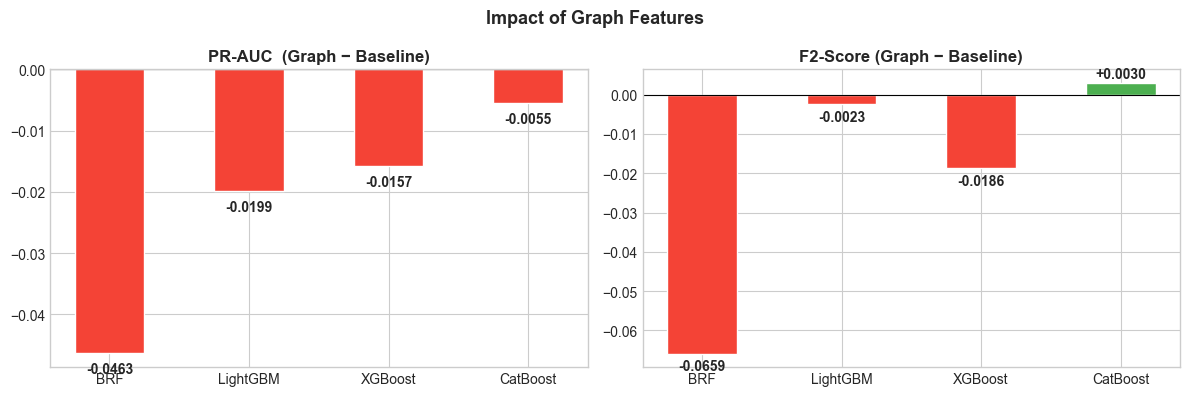

In [14]:
COLORS = {'BRF': '#2196F3', 'LightGBM': '#4CAF50', 'XGBoost': '#FF9800', 'CatBoost': '#9C27B0'}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, name in zip(axes.flatten(), MODEL_NAMES):
    c = COLORS[name]
    prec_b, rec_b, _ = precision_recall_curve(y_test, base_probs[name])
    prec_g, rec_g, _ = precision_recall_curve(y_test, graph_test_probs[name])
    auc_b = average_precision_score(y_test, base_probs[name])
    auc_g = average_precision_score(y_test, graph_test_probs[name])
    delta  = auc_g - auc_b

    ax.plot(rec_b, prec_b, color=c, linestyle='--', lw=1.8, alpha=0.7,
            label=f'Baseline (PR-AUC={auc_b:.4f})')
    ax.plot(rec_g, prec_g, color=c, linestyle='-', lw=2.5,
            label=f'Graph   (PR-AUC={auc_g:.4f})')
    ax.annotate(
        f'Δ = {"+" if delta>=0 else ""}{delta:.4f}',
        xy=(0.55, 0.10), xycoords='axes fraction', fontsize=11, fontweight='bold',
        color='green' if delta >= 0 else 'red',
        bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.85)
    )
    ax.axhline(y_test.mean(), color='gray', linestyle=':', alpha=0.5)
    ax.set(title=name, xlabel='Recall', ylabel='Precision', xlim=[0,1], ylim=[0,1.05])
    ax.legend(fontsize=9)

fig.suptitle('PR Curves — Baseline vs Graph-Enhanced (Test Set)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(DATA_PATH, '../figures/pr_curve_baseline_vs_graph.png'),
            dpi=150, bbox_inches='tight')
plt.show()

# Delta bar chart
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in [
    (axes[0], 'Δ PR-AUC', 'PR-AUC  (Graph − Baseline)'),
    (axes[1], 'Δ F2',     'F2-Score (Graph − Baseline)'),
]:
    vals = comparison_df[col].values
    bars = ax.bar(MODEL_NAMES, vals,
                  color=['#4CAF50' if v > 0 else '#F44336' for v in vals],
                  edgecolor='white', width=0.5)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_title(title, fontweight='bold')
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                v + (5e-4 if v >= 0 else -15e-4),
                f'{"+" if v>=0 else ""}{v:.4f}',
                ha='center', va='bottom' if v >= 0 else 'top',
                fontsize=10, fontweight='bold')
fig.suptitle('Impact of Graph Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
# Part 2 — Error Analysis trên False Negatives

## 6. Setup: Best Model + FN / TP

In [15]:
best_name  = max(MODEL_NAMES, key=lambda n: average_precision_score(y_test, graph_test_probs[n]))
best_probs = graph_test_probs[best_name]
best_preds = (best_probs >= 0.5).astype(int)

tn, fp, fn_count, tp_count = confusion_matrix(y_test, best_preds).ravel()
actual_fraud = (y_test == 1)
fn_mask = actual_fraud & (best_preds == 0)
tp_mask = actual_fraud & (best_preds == 1)

print(f'Best model : {best_name}  (PR-AUC={average_precision_score(y_test, best_probs):.4f})')
print(f'FN={fn_count} ({100*fn_count/actual_fraud.sum():.1f}% missed)  '
      f'TP={tp_count} ({100*tp_count/actual_fraud.sum():.1f}% caught)')

# Analysis DataFrames
test_df = pd.DataFrame(X_test_g, columns=feature_cols_g)
test_df['prob'] = best_probs
fn_df = test_df[fn_mask].copy()
tp_df = test_df[tp_mask].copy()

# Precompute for top-features analysis
analysis_cols = [c for c in feature_cols_g if c not in ('customer', 'merchant')]
fraud_df  = test_df[actual_fraud]
overall_std = fraud_df[analysis_cols].std().replace(0, 1)
fn_means    = fn_df[analysis_cols].mean()
tp_means    = tp_df[analysis_cols].mean()
norm_diff   = ((fn_means - tp_means).abs() / overall_std).sort_values(ascending=False)
top5        = norm_diff.head(5).index.tolist()

# Category decode
cat_enc = encoders['category']
def decode_cat(vals):
    return [cat_enc.classes_[int(v)] if 0 <= int(v) < len(cat_enc.classes_) else 'unknown'
            for v in vals]

fn_cats = pd.Series(decode_cat(fn_df['category'].values)).value_counts(normalize=True) * 100
tp_cats = pd.Series(decode_cat(tp_df['category'].values)).value_counts(normalize=True) * 100
all_cats = sorted(set(fn_cats.index) | set(tp_cats.index))
cat_df = pd.DataFrame({'FN %': fn_cats.reindex(all_cats, fill_value=0),
                       'TP %': tp_cats.reindex(all_cats, fill_value=0)})
cat_df['FN−TP'] = cat_df['FN %'] - cat_df['TP %']
cat_df = cat_df.sort_values('FN−TP', ascending=False)

Best model : CatBoost  (PR-AUC=0.9247)
FN=206 (21.4% missed)  TP=756 (78.6% caught)


## 7. Amount Distribution + Category Breakdown + Probability

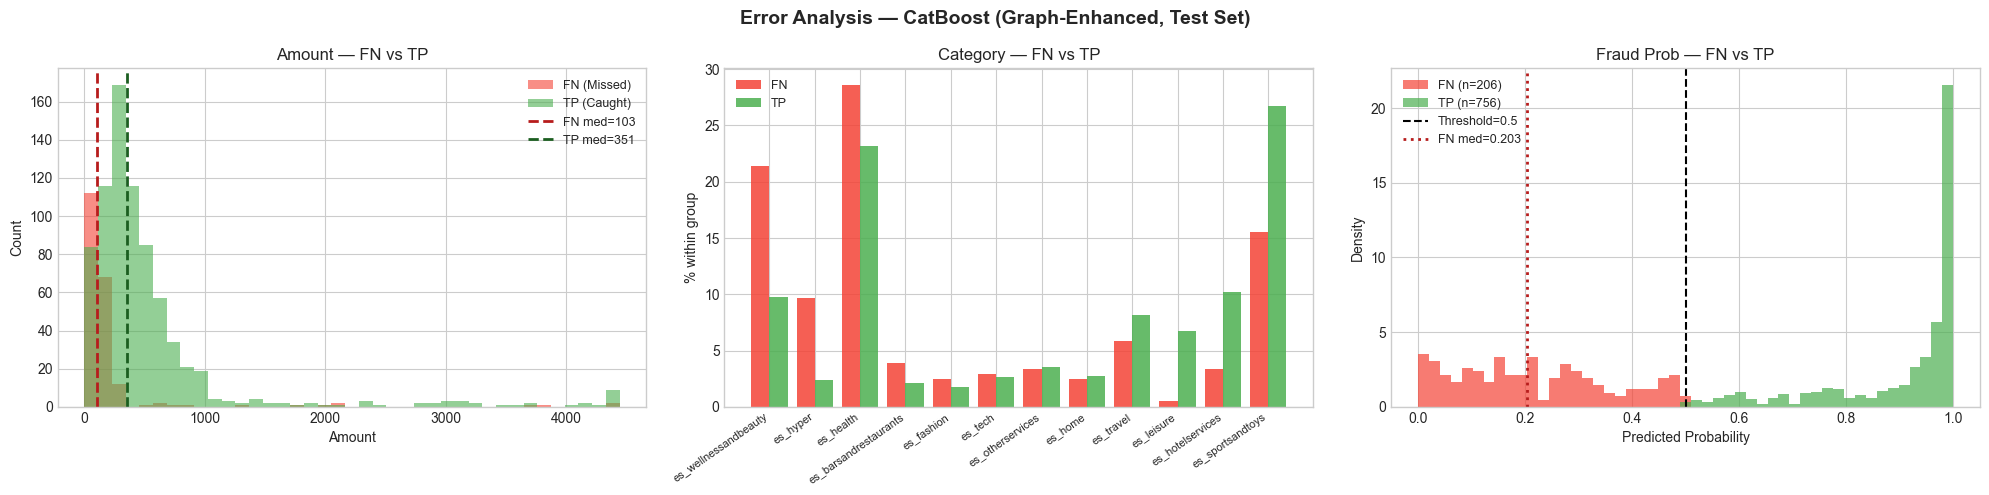

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# --- Amount histogram ---
ax = axes[0]
fn_amt, tp_amt = fn_df['amount'].values, tp_df['amount'].values
cap = np.percentile(np.concatenate([fn_amt, tp_amt]), 99)
bins = np.linspace(0, cap, 40)
ax.hist(np.clip(fn_amt, 0, cap), bins=bins, alpha=0.6, color='#F44336', label='FN (Missed)')
ax.hist(np.clip(tp_amt, 0, cap), bins=bins, alpha=0.6, color='#4CAF50', label='TP (Caught)')
ax.axvline(np.median(fn_amt), color='#B71C1C', ls='--', lw=2,
           label=f'FN med={np.median(fn_amt):.0f}')
ax.axvline(np.median(tp_amt), color='#1B5E20', ls='--', lw=2,
           label=f'TP med={np.median(tp_amt):.0f}')
ax.set(xlabel='Amount', ylabel='Count', title='Amount — FN vs TP')
ax.legend(fontsize=9)

# --- Category breakdown ---
ax2 = axes[1]
x = np.arange(len(cat_df))
ax2.bar(x - 0.2, cat_df['FN %'], width=0.4, color='#F44336', alpha=0.85, label='FN')
ax2.bar(x + 0.2, cat_df['TP %'], width=0.4, color='#4CAF50', alpha=0.85, label='TP')
ax2.set_xticks(x)
ax2.set_xticklabels(cat_df.index, rotation=35, ha='right', fontsize=8)
ax2.set(ylabel='% within group', title='Category — FN vs TP')
ax2.legend(fontsize=9)

# --- Probability distribution ---
ax3 = axes[2]
bins_p = np.linspace(0, 1, 50)
ax3.hist(fn_df['prob'].values, bins=bins_p, alpha=0.7, color='#F44336',
         density=True, label=f'FN (n={len(fn_df)})')
ax3.hist(tp_df['prob'].values, bins=bins_p, alpha=0.7, color='#4CAF50',
         density=True, label=f'TP (n={len(tp_df)})')
ax3.axvline(0.5, color='black', ls='--', lw=1.5, label='Threshold=0.5')
ax3.axvline(fn_df['prob'].median(), color='#B71C1C', ls=':', lw=2,
            label=f'FN med={fn_df["prob"].median():.3f}')
ax3.set(xlabel='Predicted Probability', ylabel='Density', title='Fraud Prob — FN vs TP')
ax3.legend(fontsize=9)

fig.suptitle(f'Error Analysis — {best_name} (Graph-Enhanced, Test Set)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Top Features + Graph Features

Top 5 features (normalised |mean_FN − mean_TP| / std):
  amount_log                      FN=4.550  TP=5.784  norm_diff=0.998  [FN<TP]
  merchant_risk                   FN=0.329  TP=0.544  norm_diff=0.717  [FN<TP]
  merchant_fraud_rate             FN=0.329  TP=0.544  norm_diff=0.717  [FN<TP]
  customer_fraud_rate             FN=0.104  TP=0.316  norm_diff=0.654  [FN<TP]
  customer_degree                 FN=9.189  TP=12.671  norm_diff=0.640  [FN<TP]


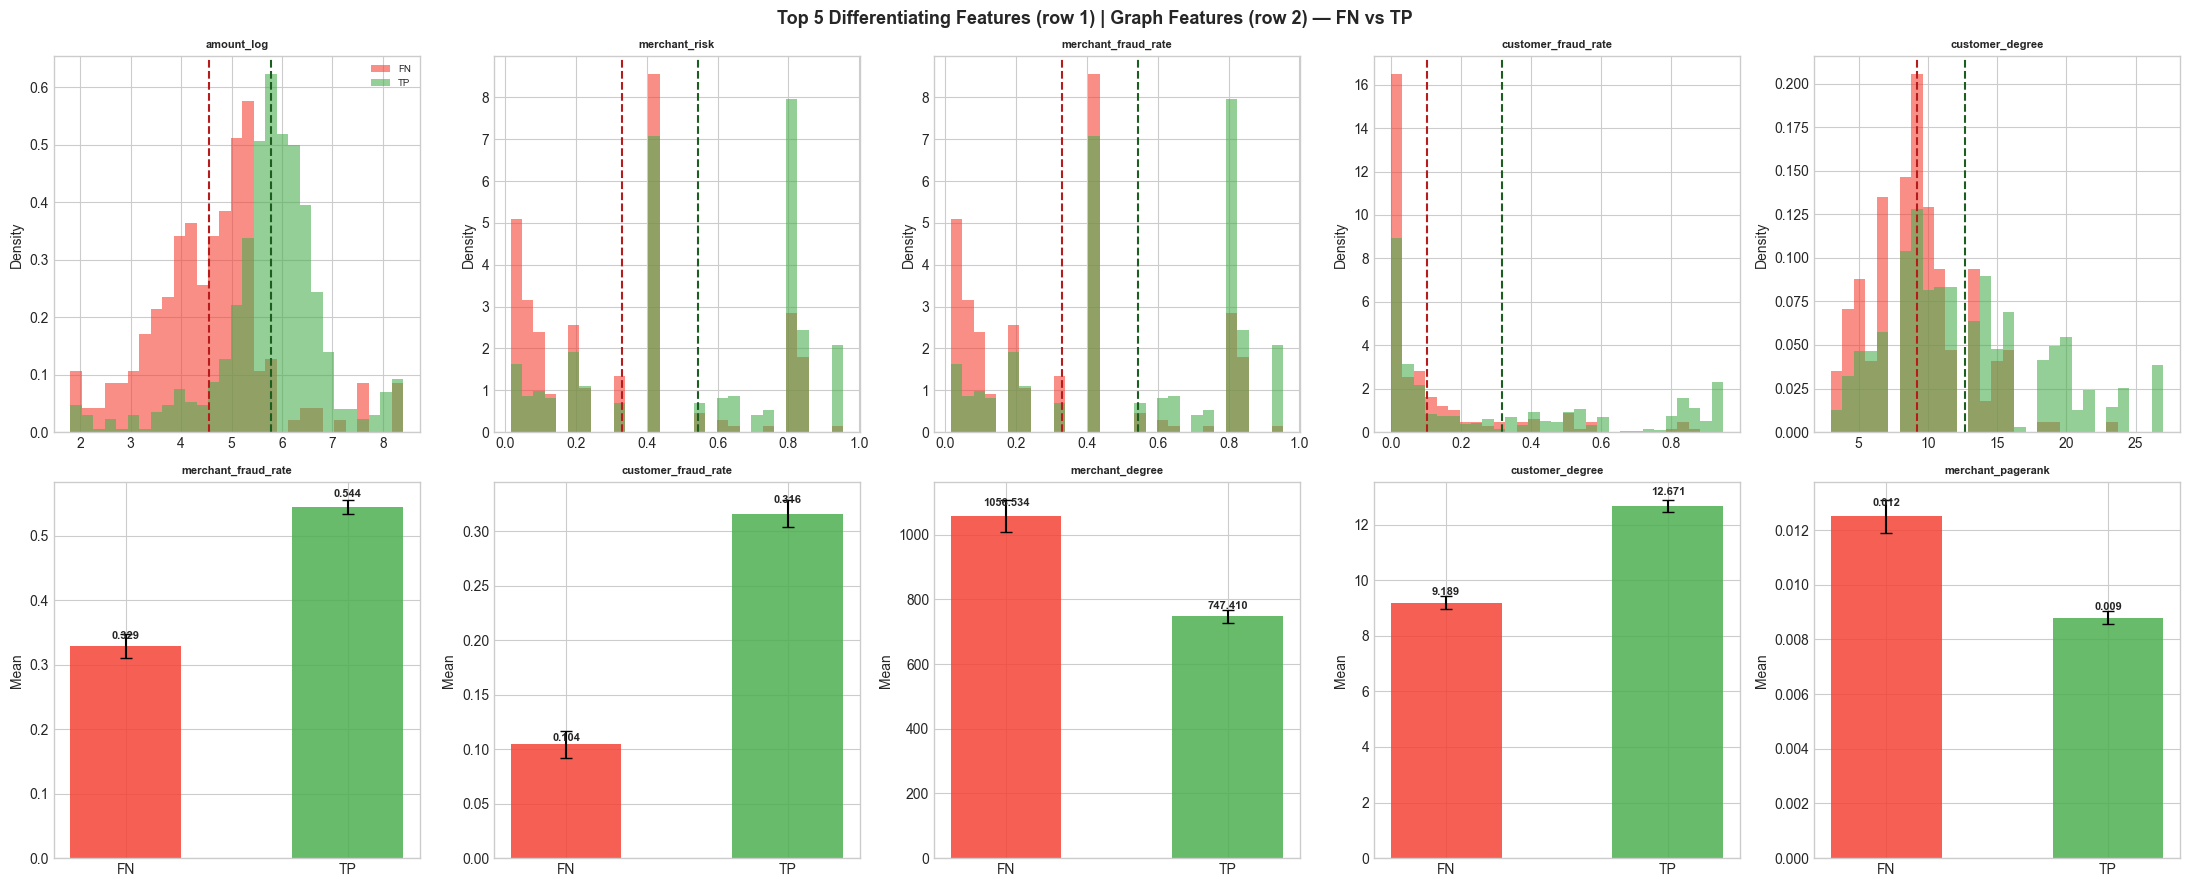

In [17]:
print('Top 5 features (normalised |mean_FN − mean_TP| / std):')
for feat in top5:
    fm, tm, nd = fn_means[feat], tp_means[feat], norm_diff[feat]
    print(f'  {feat:30s}  FN={fm:.3f}  TP={tm:.3f}  '
          f'norm_diff={nd:.3f}  [{"FN>TP" if fm>tm else "FN<TP"}]')

# Top 5 histograms + graph fraud-rate bars in one figure
fig = plt.figure(figsize=(22, 9))

# Row 1: top-5 feature histograms
for i, feat in enumerate(top5):
    ax = fig.add_subplot(2, 5, i + 1)
    fn_v, tp_v = fn_df[feat].values, tp_df[feat].values
    lo, hi = np.percentile(np.concatenate([fn_v, tp_v]), [1, 99])
    bins_f = np.linspace(lo, hi, 30)
    ax.hist(np.clip(fn_v, lo, hi), bins=bins_f, alpha=0.6, color='#F44336',
            density=True, label='FN')
    ax.hist(np.clip(tp_v, lo, hi), bins=bins_f, alpha=0.6, color='#4CAF50',
            density=True, label='TP')
    ax.axvline(fn_v.mean(), color='#B71C1C', ls='--', lw=1.5)
    ax.axvline(tp_v.mean(), color='#1B5E20', ls='--', lw=1.5)
    ax.set_title(feat, fontsize=8, fontweight='bold')
    ax.set_ylabel('Density')
    if i == 0:
        ax.legend(fontsize=7)

# Row 2: graph fraud-rate features — mean bar comparison
graph_feats = ['merchant_fraud_rate', 'customer_fraud_rate',
               'merchant_degree',     'customer_degree',     'merchant_pagerank']
for j, feat in enumerate(graph_feats):
    ax = fig.add_subplot(2, 5, 6 + j)
    fn_v, tp_v = fn_df[feat].values, tp_df[feat].values
    means = [fn_v.mean(), tp_v.mean()]
    sems  = [fn_v.std() / np.sqrt(len(fn_v)), tp_v.std() / np.sqrt(len(tp_v))]
    bars  = ax.bar(['FN', 'TP'], means, yerr=sems, capsize=4,
                   color=['#F44336', '#4CAF50'], alpha=0.85, width=0.5)
    for bar, m in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width()/2, m * 1.03,
                f'{m:.3f}', ha='center', fontsize=8, fontweight='bold')
    ax.set_title(feat, fontsize=8, fontweight='bold')
    ax.set_ylabel('Mean')

fig.suptitle('Top 5 Differentiating Features (row 1) | Graph Features (row 2) — FN vs TP',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()